Enter x1: 2
Enter y1: 3
Enter x2: 3
Enter y2: 4


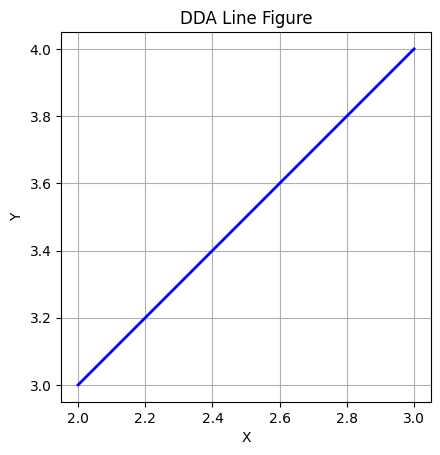

In [5]:
import matplotlib.pyplot as plt

def dda_algorithm(x1, y1, x2, y2):
    # Step 3: Find the differentiation
    dx = x2 - x1
    dy = y2 - y1

    # Step 4: Find the number of steps
    steps = int(max(abs(dx), abs(dy)))

    # Step 6: Calculate Increment
    x_inc = dx / steps
    y_inc = dy / steps

    # Step 5: Start at (x1, y1)
    x = x1
    y = y1

    x_points = []
    y_points = []

    # Step 6 & 7: Repeat until final point
    for _ in range(steps + 1):
        x_points.append(round(x))
        y_points.append(round(y))
        x = x + x_inc
        y = y + y_inc

    return x_points, y_points

# Step 2: Take input
x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))
x2 = int(input("Enter x2: "))
y2 = int(input("Enter y2: "))

# Function Call
x_pts, y_pts = dda_algorithm(x1, y1, x2, y2)

# Plot Figure (Continuous line)
plt.figure()
plt.plot(x_pts, y_pts, color='blue', linewidth=2)
plt.title("DDA Line Figure")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

Enter x0: 54
Enter y0: 55
Enter x1: 50
Enter y1: 56


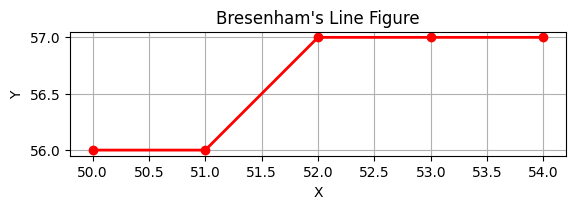

In [9]:
import matplotlib.pyplot as plt

def bresenham_algorithm(x0, y0, x1, y1):
    # Step 1 Requirement: Ensure (x0, y0) is the left endpoint (x0 <= x1)
    if x0 > x1:
        x0, x1 = x1, x0
        y0, y1 = y1, y0

    # Step 3: Calculate constants
    dx = abs(x1 - x0)
    dy = abs(y1 - y0)

    two_dy = 2 * dy
    two_dy_minus_two_dx = 2 * dy - 2 * dx

    # Step 4: Initial decision parameter
    p = two_dy - dx

    # Step 2: Plot the first point (x0, y0)
    x = x0
    y = y0

    x_points = [x]
    y_points = [y]

    # Step 5 & 6: Repeat until endpoint
    while x < x1:
        x = x + 1
        if p < 0:
            p = p + two_dy
        else:
            y = y + 1
            p = p + two_dy_minus_two_dx

        x_points.append(x)
        y_points.append(y)

    return x_points, y_points

# Step 1: Input endpoints
x0 = int(input("Enter x0: "))
y0 = int(input("Enter y0: "))
x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))

# Function Call
x_pts, y_pts = bresenham_algorithm(x0, y0, x1, y1)

# Plot Figure
plt.figure()
plt.plot(x_pts, y_pts, color='red', linewidth=2, marker='o')
plt.title("Bresenham's Line Figure")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

Enter radius (r): 4


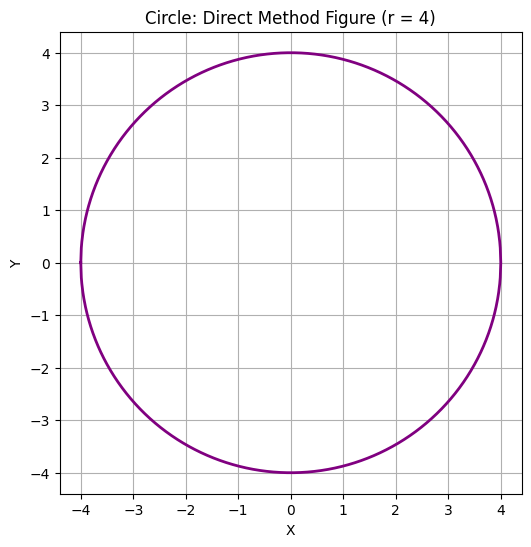

In [11]:
import math
import matplotlib.pyplot as plt

def circle_direct_method(r, step=0.01):
    upper_x, upper_y = [], []
    lower_x, lower_y = [], []

    # Step smoothly from -r to r using a fine step size
    x = -float(r)
    while x <= r:
        # Teacher's exact formula: y = sqrt(r^2 - x^2)
        y = math.sqrt(max(0.0, r**2 - x**2))

        upper_x.append(x)
        upper_y.append(y)

        lower_x.append(x)
        lower_y.append(-y)

        x = x + step

    # Connect upper arc left-to-right, then lower arc right-to-left to close circle
    x_points = upper_x + lower_x[::-1] + [upper_x[0]]
    y_points = upper_y + lower_y[::-1] + [upper_y[0]]

    return x_points, y_points

# Input
r = int(input("Enter radius (r): "))

# Function Call
x_pts, y_pts = circle_direct_method(r)

# Plot Figure
plt.figure(figsize=(6, 6))
plt.plot(x_pts, y_pts, color='purple', linewidth=2)
plt.title(f"Circle: Direct Method Figure (r = {r})")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

Enter radius (r): 4


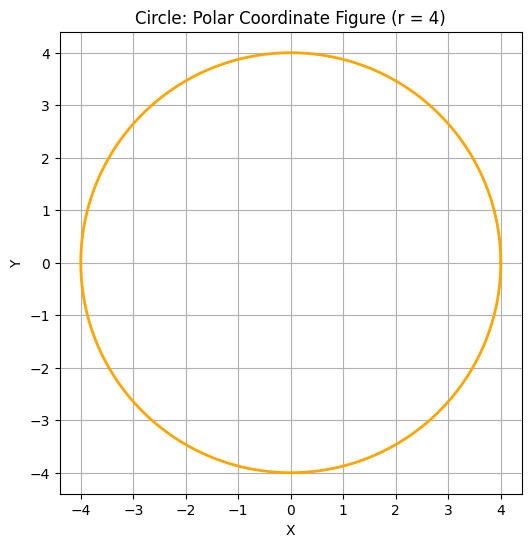

In [13]:
import math
import matplotlib.pyplot as plt

def circle_polar_method(r, step_deg=1):
    x_points = []
    y_points = []

    # Vary theta from 0 to 360 degrees
    theta = 0
    while theta <= 360:
        rad = math.radians(theta)

        # Teacher's exact formula: x = r*cos(theta), y = r*sin(theta)
        x = r * math.cos(rad)
        y = r * math.sin(rad)

        x_points.append(x)
        y_points.append(y)

        theta = theta + step_deg

    return x_points, y_points

# Input
r = int(input("Enter radius (r): "))

# Function Call
x_pts, y_pts = circle_polar_method(r)

# Plot Figure
plt.figure(figsize=(6, 6))
plt.plot(x_pts, y_pts, color='orange', linewidth=2)
plt.title(f"Circle: Polar Coordinate Figure (r = {r})")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

Enter radius (r): 4


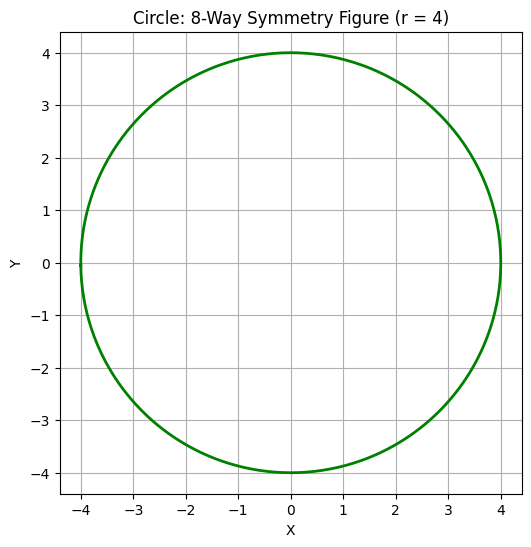

In [14]:
import math
import matplotlib.pyplot as plt

def circle_8way_symmetry(r):
    pts = []

    def add_8_symmetric_points(x, y):
        # Teacher's exact 8-way symmetry points from lecture notes:
        # (x,y), (y,x), (-x,y), (-y,x), (-x,-y), (-y,-x), (x,-y), (y,-x)
        octants = [
            (x, y),   (y, x),   (-x, y),  (-y, x),
            (-x, -y), (-y, -x), (x, -y),  (y, -x)
        ]
        pts.extend(octants)

    # Midpoint decision for the first octant (0 to 45 degrees)
    # Using continuous sub-stepping along the arc to prevent angular flat edges
    step = 0.05
    x = 0.0
    y = float(r)

    while x <= y:
        add_8_symmetric_points(x, y)
        x += step
        y = math.sqrt(max(0.0, r**2 - x**2))

    # Sort perimeter points radially (0 to 2*pi) so the plotted line traces a smooth loop
    pts = sorted(list(set(pts)), key=lambda p: math.atan2(p[1], p[0]))
    pts.append(pts[0])  # Close the path

    x_points = [p[0] for p in pts]
    y_points = [p[1] for p in pts]

    return x_points, y_points

# Input
r = int(input("Enter radius (r): "))

# Function Call
x_pts, y_pts = circle_8way_symmetry(r)

# Plot Figure
plt.figure(figsize=(6, 6))
plt.plot(x_pts, y_pts, color='green', linewidth=2)
plt.title(f"Circle: 8-Way Symmetry Figure (r = {r})")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

Enter x1: 4
Enter y1: 5
Enter x2: 5
Enter y2: 6
Enter x3: 8
Enter y3: 9
Enter x4: 4
Enter y4: 5


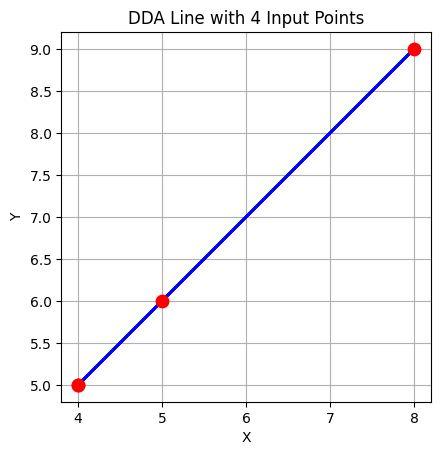

In [21]:
import matplotlib.pyplot as plt

def dda_algorithm(x1, y1, x2, y2):
    dx = x2 - x1
    dy = y2 - y1
    steps = int(max(abs(dx), abs(dy)))

    if steps == 0:
        return [x1], [y1]

    x_inc = dx / steps
    y_inc = dy / steps

    x = x1
    y = y1
    x_points = []
    y_points = []

    for _ in range(steps + 1):
        x_points.append(round(x))
        y_points.append(round(y))
        x += x_inc
        y += y_inc

    return x_points, y_points

# Helper to avoid crash if Enter is pressed on empty input
def get_int(prompt):
    val = input(prompt).strip()
    return int(val) if val != "" else 0

# Input 4 Points
x1 = get_int("Enter x1: ")
y1 = get_int("Enter y1: ")
x2 = get_int("Enter x2: ")
y2 = get_int("Enter y2: ")
x3 = get_int("Enter x3: ")
y3 = get_int("Enter y3: ")
x4 = get_int("Enter x4: ")
y4 = get_int("Enter y4: ")

# DDA Lines connecting P1 -> P2 -> P3 -> P4
x_line, y_line = [], []
segments = [((x1, y1), (x2, y2)), ((x2, y2), (x3, y3)), ((x3, y3), (x4, y4))]

for start, end in segments:
    pts_x, pts_y = dda_algorithm(start[0], start[1], end[0], end[1])
    x_line.extend(pts_x)
    y_line.extend(pts_y)

# Plotting
plt.figure()
plt.plot(x_line, y_line, color='blue', linewidth=2)
plt.scatter([x1, x2, x3, x4], [y1, y2, y3, y4], color='red', s=80, zorder=5)

plt.title("DDA Line with 4 Input Points")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

Enter x1: 4
Enter y1: 5
Enter x2: 6
Enter y2: 7
Enter x3: 8
Enter y3: 5
Enter x4: 4
Enter y4: 6


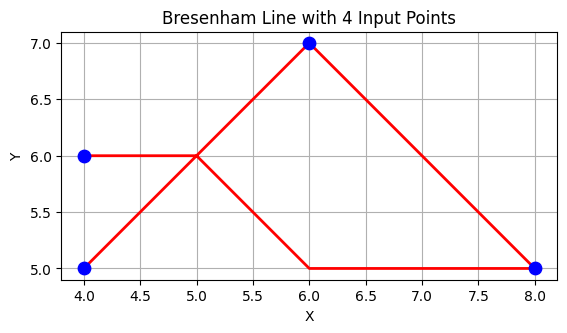

In [22]:
import matplotlib.pyplot as plt

def bresenham_algorithm(x0, y0, x1, y1):
    dx = abs(x1 - x0)
    dy = abs(y1 - y0)

    sx = 1 if x0 < x1 else -1
    sy = 1 if y0 < y1 else -1

    err = dx - dy
    x = x0
    y = y0

    x_points = []
    y_points = []

    while True:
        x_points.append(x)
        y_points.append(y)

        if x == x1 and y == y1:
            break

        e2 = 2 * err
        if e2 > -dy:
            err -= dy
            x += sx
        if e2 < dx:
            err += dx
            y += sy

    return x_points, y_points

# Helper to prevent crashes if Enter is pressed accidentally on an empty line
def get_int(prompt):
    val = input(prompt).strip()
    return int(val) if val != "" else 0

# Input 4 Points (8 coordinate values)
x1 = get_int("Enter x1: ")
y1 = get_int("Enter y1: ")
x2 = get_int("Enter x2: ")
y2 = get_int("Enter y2: ")
x3 = get_int("Enter x3: ")
y3 = get_int("Enter y3: ")
x4 = get_int("Enter x4: ")
y4 = get_int("Enter y4: ")

# Bresenham Lines connecting P1 -> P2 -> P3 -> P4
x_line, y_line = [], []
segments = [((x1, y1), (x2, y2)), ((x2, y2), (x3, y3)), ((x3, y3), (x4, y4))]

for start, end in segments:
    pts_x, pts_y = bresenham_algorithm(start[0], start[1], end[0], end[1])
    x_line.extend(pts_x)
    y_line.extend(pts_y)

# Plotting
plt.figure()
# 1. Draw Bresenham Line
plt.plot(x_line, y_line, color='red', linewidth=2)

# 2. Mark ONLY the 4 input points
plt.scatter([x1, x2, x3, x4], [y1, y2, y3, y4], color='blue', s=80, zorder=5)

plt.title("Bresenham Line with 4 Input Points")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()